In [2]:
import requests
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
url = "https://air-quality-api.open-meteo.com/v1/air-quality"

latitude = 17.3850
longitude = 78.4867

print("Location: Hyderabad")
print("Latitude:", latitude)
print("Longitude:", longitude)

Location: Hyderabad
Latitude: 17.385
Longitude: 78.4867


In [4]:
params = {
    "latitude": latitude,
    "longitude": longitude,
    "hourly": "pm10,pm2_5,carbon_monoxide,nitrogen_dioxide,sulphur_dioxide,ozone,us_aqi",
    "timezone": "Asia/Kolkata",
    "forecast_days": 5
}

response = requests.get(url, params=params)

print("Status Code:", response.status_code)

Status Code: 200


In [5]:
data = response.json()

hourly_data = data["hourly"]

print(hourly_data.keys())

dict_keys(['time', 'pm10', 'pm2_5', 'carbon_monoxide', 'nitrogen_dioxide', 'sulphur_dioxide', 'ozone', 'us_aqi'])


In [6]:
time = hourly_data["time"]

pm10 = hourly_data["pm10"]

pm25 = hourly_data["pm2_5"]

co = hourly_data["carbon_monoxide"]

no2 = hourly_data["nitrogen_dioxide"]

so2 = hourly_data["sulphur_dioxide"]

ozone = hourly_data["ozone"]

aqi = hourly_data["us_aqi"]

In [7]:
df = pd.DataFrame({
    "Date_Time": time,
    "PM10": pm10,
    "PM2.5": pm25,
    "CO": co,
    "NO2": no2,
    "SO2": so2,
    "Ozone": ozone,
    "AQI": aqi
})

df.head()

,Date_Time,PM10,PM2.5,CO,NO2,SO2,Ozone,AQI
0,2026-11-01T00:00,37.4,36.3,433.0,12.4,10.2,76.0,90
1,2026-11-01T01:00,34.9,34.1,381.0,9.2,9.8,79.0,90
2,2026-11-01T02:00,31.1,30.3,352.0,6.8,9.6,82.0,91
3,2026-11-01T03:00,28.8,28.1,345.0,6.0,9.8,81.0,91
4,2026-11-01T04:00,27.0,26.4,361.0,6.1,10.3,78.0,91


In [8]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")

df.info()

Dataset Shape: (120, 8)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 8 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Date_Time  120 non-null    str    
 1   PM10       120 non-null    float64
 2   PM2.5      120 non-null    float64
 3   CO         120 non-null    float64
 4   NO2        120 non-null    float64
 5   SO2        120 non-null    float64
 6   Ozone      120 non-null    float64
 7   AQI        120 non-null    int64  
dtypes: float64(6), int64(1), str(1)
memory usage: 7.6 KB


In [9]:
df.isnull().sum()

Date_Time    0
PM10         0
PM2.5        0
CO           0
NO2          0
SO2          0
Ozone        0
AQI          0
dtype: int64

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df.describe()

,PM10,PM2.5,CO,NO2,SO2,Ozone,AQI
count,120.0000,120.000000,120.000000,120.000000,120.000000,120.000000,120.000000
mean,11.9900,11.636667,495.890000,8.074167,7.163333,73.433333,53.308333
std,8.4121,8.205562,242.387361,5.959986,2.612219,25.703132,22.211283
min,2.2000,2.200000,215.000000,1.300000,3.600000,29.000000,24.000000
25%,5.1750,4.800000,319.375000,4.475000,5.000000,52.750000,32.750000
50%,8.3000,8.000000,422.500000,7.200000,6.350000,68.500000,52.000000
75%,18.2000,17.450000,612.750000,9.775000,9.125000,89.000000,71.250000
max,37.4000,36.300000,1269.000000,33.400000,15.200000,143.000000,91.000000


In [12]:
df.to_csv("Hyderabad_Air_Quality.csv", index=False)

print("Air Quality Dataset Saved Successfully!")

Air Quality Dataset Saved Successfully!


In [13]:
air_quality = pd.read_csv("Hyderabad_Air_Quality.csv")

air_quality.head(10)

,Date_Time,PM10,PM2.5,CO,NO2,SO2,Ozone,AQI
0,2026-11-01T00:00,37.4,36.3,433.0,12.4,10.2,76.0,90
1,2026-11-01T01:00,34.9,34.1,381.0,9.2,9.8,79.0,90
2,2026-11-01T02:00,31.1,30.3,352.0,6.8,9.6,82.0,91
3,2026-11-01T03:00,28.8,28.1,345.0,6.0,9.8,81.0,91
4,2026-11-01T04:00,27.0,26.4,361.0,6.1,10.3,78.0,91
5,2026-11-01T05:00,10.7,10.5,379.0,4.2,11.1,91.0,91
6,2026-11-01T06:00,12.3,12.1,401.0,4.5,11.3,94.0,90
7,2026-11-01T07:00,12.9,12.5,426.0,4.9,11.5,98.0,89
8,2026-11-01T08:00,15.5,14.9,431.0,4.9,11.2,103.0,88
9,2026-11-01T09:00,17.6,16.9,398.0,4.0,10.1,111.0,88


In [14]:
print("Total Records:", len(df))
print("Total Columns:", len(df.columns))

print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst 5 Records:")
print(df.head())

Total Records: 120
Total Columns: 8

Column Names:
['Date_Time', 'PM10', 'PM2.5', 'CO', 'NO2', 'SO2', 'Ozone', 'AQI']

First 5 Records:
          Date_Time  PM10  PM2.5     CO   NO2   SO2  Ozone  AQI
0  2026-11-01T00:00  37.4   36.3  433.0  12.4  10.2   76.0   90
1  2026-11-01T01:00  34.9   34.1  381.0   9.2   9.8   79.0   90
2  2026-11-01T02:00  31.1   30.3  352.0   6.8   9.6   82.0   91
3  2026-11-01T03:00  28.8   28.1  345.0   6.0   9.8   81.0   91
4  2026-11-01T04:00  27.0   26.4  361.0   6.1  10.3   78.0   91


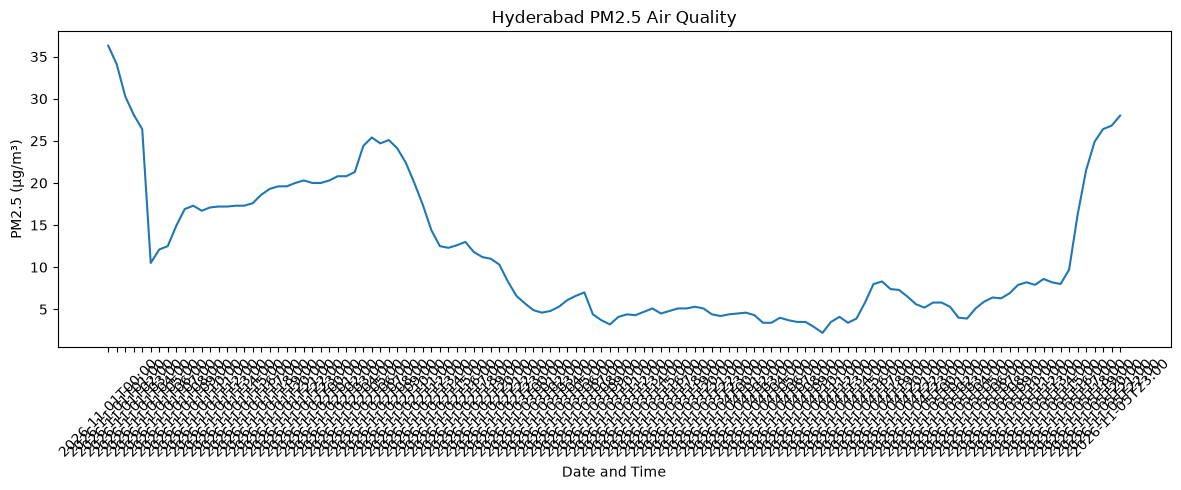

In [15]:
plt.figure(figsize=(12, 5))

plt.plot(df["Date_Time"], df["PM2.5"])

plt.title("Hyderabad PM2.5 Air Quality")
plt.xlabel("Date and Time")
plt.ylabel("PM2.5 (µg/m³)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [16]:
print("CODEALPHA TASK 1 COMPLETED")
print("Project: Air Quality Web Data Collection")
print("Location: Hyderabad")
print("Method: Python Requests API")
print("Dataset: Hyderabad_Air_Quality.csv")

CODEALPHA TASK 1 COMPLETED
Project: Air Quality Web Data Collection
Location: Hyderabad
Method: Python Requests API
Dataset: Hyderabad_Air_Quality.csv


In [17]:
from bs4 import BeautifulSoup


In [18]:
html_url = "https://www.data.gov.in/catalog/real-time-air-quality-index"

headers = {
    "User-Agent": "Mozilla/5.0"
}

html_response = requests.get(html_url, headers=headers, timeout=30)

print("Status Code:", html_response.status_code)

Status Code: 200


In [19]:
soup = BeautifulSoup(html_response.text, "html.parser")

print("Website Title:")
print(soup.title.get_text(strip=True) if soup.title else "Title not found")

Website Title:
Real time Air Quality Index | Open Government Data (OGD) Platform India


In [20]:
headings = soup.find_all(["h1", "h2", "h3"])

for heading in headings:
    print(heading.get_text(strip=True))

Open Government Data Portal India
Real time Air Quality Index
No Result Found...
Shri Bharat Sharma


In [21]:
links = soup.find_all("a", href=True)

for link in links[:20]:
    print(link.get_text(strip=True), ":", link["href"])

 : javascript:void(0)
Choose your theme : javascript:void(0)
Select default-theme : javascript:void(0)
Select blue-theme : javascript:void(0)
Select yellow-theme : javascript:void(0)
Select green-theme : javascript:void(0)
Facebook : https://www.facebook.com/dataportalofindia
Twitter : https://twitter.com/DataPortalIndia
RSS : https://data.gov.in/backend/dms/v1/rss.xml
Accessibility Dropdown : javascript:void(0)
A : javascript:void(0)
A+ : javascript:void(0)
A : javascript:void(0)
A- : javascript:void(0)
Open Government Data Portal India : /
Notifications00
                            NewNotificationAll(0)Unread(0)No NotificationNo records foundView All : javascript:void(0)
Login | Register : https://www.data.gov.in/backend/authmid/v1/login?r=&provider=Janparichay
Dashboard : /dashboard
User : #
Logout : /oauth/logout


In [22]:
print("HTML SCRAPING COMPLETED")
print("Website: data.gov.in")
print("Tool: BeautifulSoup")
print("Total headings:", len(headings))
print("Total links:", len(links))

HTML SCRAPING COMPLETED
Website: data.gov.in
Tool: BeautifulSoup
Total headings: 4
Total links: 101
